# Intelligent University Student Complaint Analysis and Routing Using Machine Learning and Multi-Task Deep Learning

## 1. Introduction

### 1.1 Background and Motivation

Artificial Intelligence (AI) and Natural Language Processing (NLP) are increasingly used to automate the interpretation, classification, and management of textual information. Educational institutions receive numerous messages from students concerning academic procedures, examination schedules, administrative services, accommodation facilities, financial transactions, campus safety, and other university-related issues. Processing these messages manually can require considerable administrative effort, particularly when each complaint must be interpreted, prioritized, and assigned to the appropriate department.

An intelligent complaint management system can support university administrators by identifying the main subject of an incoming complaint, estimating its urgency, analyzing its emotional tone, and recommending the responsible department. Such a system has the potential to improve the consistency of complaint processing, reduce repetitive classification tasks, and support more efficient handling of student requests.

However, automatic complaint classification introduces several challenges. Student messages may contain informal expressions, grammatical variations, ambiguous descriptions, emotional language, and incomplete information. Furthermore, incorrect routing may delay the resolution of important problems, while inaccurate urgency predictions may cause potentially serious complaints to receive insufficient attention.

These challenges are particularly relevant to the Kazakh language, which has more limited publicly available labeled NLP resources than widely studied languages such as English. Kazakh also has rich morphological structures, including extensive suffixation, which can make traditional word-based text representations less effective.

This project investigates whether classical machine learning, recurrent neural networks, and pretrained Transformer architectures can effectively classify university student complaints written in Kazakh and support automated complaint routing.

### 1.2 Problem Statement

The primary problem addressed in this study is the automatic interpretation and routing of university student complaints written in natural Kazakh text.

Rather than treating complaint classification as a single-label prediction problem, this project considers four interconnected tasks:

1. **Category Classification:** Identifying whether a complaint concerns academic processes, administrative services, or the campus environment.
2. **Urgency Classification:** Estimating the priority level of a complaint as low, medium, or high.
3. **Tone Classification:** Recognizing the emotional tone of the complaint as neutral, dissatisfied, or intensely negative.
4. **Department Classification:** Predicting the university department responsible for reviewing and resolving the issue.

These tasks are related but represent different aspects of an incoming complaint. A message concerning an examination schedule, for example, may belong to the academic category while simultaneously expressing dissatisfaction and requiring urgent administrative attention.

A reliable intelligent system should therefore analyze several attributes of a complaint instead of relying on a single classification result.

In addition, model predictions must be incorporated into a practical routing mechanism that can automatically process sufficiently confident cases while referring uncertain or potentially urgent cases for human review.

### 1.3 Research Aim

The main aim of this project is to design, implement, evaluate, and compare machine learning and deep learning approaches for multi-dimensional classification and intelligent routing of university student complaints in Kazakh.

The project also seeks to investigate the relationship between model complexity, classification performance, and practical suitability for automated administrative decision support.

An additional objective is to examine whether more computationally expensive neural architectures provide measurable benefits over simpler machine learning techniques when the available labeled dataset is relatively small.

### 1.4 Research Objectives

To achieve the research aim, the following objectives are established:

1. Explore and analyze a labeled dataset of university student complaints written in Kazakh.
2. Examine class distributions, text lengths, missing values, duplicate records, and textual similarities.
3. Apply appropriate preprocessing and normalization while preserving important linguistic characteristics of Kazakh.
4. Prepare reproducible training, validation, and test datasets.
5. Implement a classical text classification baseline using character-level TF-IDF features and Linear Support Vector Machines.
6. Develop a neural text classification architecture based on Bidirectional Long Short-Term Memory (BiLSTM) networks with an attention mechanism.
7. Fine-tune the multilingual XLM-RoBERTa Transformer for four classification tasks.
8. Fine-tune a Kazakh-specific RoBERTa model using a shared encoder and multiple classification heads.
9. Compare the models using Accuracy, Precision, Recall, Macro-F1, and confusion matrices.
10. Investigate model errors, particularly cases in which high-urgency complaints are incorrectly classified.
11. Develop a confidence-aware routing mechanism with manual review for uncertain predictions.
12. Examine the trade-off between automatic routing coverage and routing accuracy.
13. Export trained model artifacts for integration into a separate practical application.

### 1.5 Dataset Description

The experiments use a labeled dataset containing **1,000 university student complaints written in Kazakh**.

The original dataset contains six columns: a record identifier, complaint text, category, urgency, tone, and responsible department.

Each complaint is associated with four target labels, allowing the implementation of both independent classifiers and multi-task neural architectures.

The dataset contains:

| Target | Number of Classes | Description |
|---|---:|---|
| Category | 3 | Academic process, administrative services, campus environment |
| Urgency | 3 | Low, medium, high |
| Tone | 3 | Neutral, dissatisfied, intense negative |
| Department | 6 | Six university administrative or service departments |

The category and department labels are approximately balanced. However, the urgency and tone labels have unequal distributions, making macro-averaged evaluation metrics particularly important.

The dataset contains no missing values or exact duplicate complaint texts in the initial analysis. The average complaint length is approximately 201 characters or 25 words.

A similarity analysis nevertheless identifies several pairs of texts with highly similar structures. This suggests that repeated textual patterns may exist even when complaints are not exact duplicates.

Consequently, model evaluation must be interpreted with caution, especially when considering performance on naturally occurring student complaints.

### 1.6 Data Preprocessing and Experimental Design

The preprocessing stage applies Unicode NFC normalization, removes selected invisible characters, and standardizes unnecessary whitespace. Important Kazakh characters, punctuation, and linguistic expressions are preserved.

The dataset is divided into three subsets:

| Subset | Samples | Percentage |
|---|---:|---:|
| Training | 700 | 70% |
| Validation | 150 | 15% |
| Testing | 150 | 15% |

The split uses a fixed random seed of 42 and stratification based on combinations of complaint category and urgency.

The training set is used for model parameter optimization. The validation set is used for hyperparameter selection, model checkpoint selection, and routing threshold experiments. The test set is reserved for the final model comparison.

A separate text similarity analysis examines potentially overlapping patterns between the subsets. Although exact duplicates are absent, some highly similar complaints appear across the partitions. This is acknowledged as a limitation of the experimental design.

### 1.7 Machine Learning and Deep Learning Models

Four different modeling approaches are investigated in this project.

**Model 1: TF-IDF + Linear Support Vector Machine**

The first approach uses character-level TF-IDF features with a Linear Support Vector Machine (Linear SVM).

Character n-grams are useful for morphologically rich languages because they can represent recurring word fragments, suffixes, and spelling variations.

Four separate classifiers are trained, one for each target label. Different regularization values are evaluated using the validation dataset.

This model serves as the classical machine learning baseline.

**Model 2: BiLSTM with Attention**

The second approach uses a Bidirectional Long Short-Term Memory network combined with an attention mechanism.

The BiLSTM processes word sequences in both directions, while attention allows the model to assign different importance weights to individual tokens.

The architecture uses a shared textual representation and four output heads for multi-task classification.

Unlike the pretrained Transformer models, its word embeddings are learned from the available training data.

**Model 3: XLM-RoBERTa**

The third approach fine-tunes XLM-RoBERTa-base, a multilingual Transformer model with approximately 278 million parameters in the implemented architecture.

The pretrained encoder produces contextual text representations, which are combined with four task-specific linear classification heads.

The model is optimized using AdamW, learning rate scheduling, gradient accumulation, and mixed-precision training.

This experiment evaluates the effectiveness of a large multilingual Transformer on a relatively small Kazakh dataset.

**Model 4: KazRoBERTa Multi-Task Learning**

The fourth approach fine-tunes KazRoBERTa, a Transformer pretrained specifically for Kazakh-language processing.

The implemented architecture contains approximately 83.5 million parameters and shares its encoder across all four classification tasks.

The shared contextual representation is passed through dropout and separate linear output heads.

The multi-task training objective combines the classification losses of category, urgency, tone, and department prediction.

This approach is intended to investigate the suitability of language-specific pretrained representations for automated university complaint analysis.

### 1.8 Evaluation Methodology

Model performance is measured using several complementary metrics.

**Accuracy** measures the overall proportion of correctly classified examples.

**Precision** measures the proportion of predicted instances of a class that are correct.

**Recall** measures how many actual instances of a class are successfully identified.

**Macro-F1** calculates the arithmetic mean of class-level F1-scores, giving equal importance to each class regardless of its frequency.

Macro-F1 is emphasized because the urgency and emotional tone distributions are not perfectly balanced.

Confusion matrices are generated to examine which classes are most frequently confused.

Training and validation loss curves are also analyzed to investigate convergence and possible overfitting.

The models are compared separately for each classification task, as well as through the mean of the four task-level Macro-F1 scores.

Special attention is given to high-urgency complaints because incorrectly predicting such cases as medium or low urgency may have more serious operational consequences than ordinary classification errors.

### 1.9 Confidence-Aware Routing

Beyond classification, the project investigates an intelligent routing mechanism.

The routing component uses the predicted category, urgency, and department together with the model's output probabilities to decide whether a complaint should be routed automatically or referred for manual review.

A confidence score is calculated from the classification outputs, and different confidence thresholds are evaluated on the validation dataset.

The routing experiment measures:

- Automatic routing coverage.
- Accuracy among automatically routed complaints.
- Proportion of cases requiring manual review.
- Number of high-urgency complaints incorrectly handled without appropriate escalation.

An additional probability-based condition is used to flag complaints with a potentially high urgency level.

This routing mechanism is presented as a research prototype rather than a fully validated production system. Its confidence values are not independently calibrated probabilities, and its example service-level targets are illustrative rather than official university policies.

### 1.10 Expected Contribution and Project Scope

The main contribution of this project is a comparative experimental framework combining classical machine learning, recurrent deep learning, multilingual Transformers, and Kazakh-specific Transformer architectures for university complaint analysis.

The work demonstrates how several language understanding tasks can be addressed within a common research pipeline and how their predictions can support practical routing decisions.

The project emphasizes reproducible experiments, transparent evaluation, comparative performance analysis, error identification, and responsible AI considerations.

The Google Colab notebook covers dataset analysis, preprocessing, model training, validation, testing, and routing experiments.

A separate Streamlit application is planned to provide an interactive interface for using the exported model in a practical complaint analysis scenario.

This separation distinguishes the scientific experimentation process from the deployment-oriented application.

Overall, the project aims to demonstrate both the possibilities and limitations of applying modern AI methods to Kazakh-language administrative text classification and intelligent decision support.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

from google.colab import files

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

uploaded = files.upload()

filename = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if filename is None:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving university_student_complaints_dedup.csv to university_student_complaints_dedup.csv
Dataset shape: (1000, 6)
Columns: ['id', 'text_kk', 'category', 'urgency', 'tone', 'department']


,id,text_kk,category,urgency,tone,department
0,1,Соңғы уақытта пәнге тіркелу жүйесі өтінімді қа...,academic_process,medium,neutral,academic_affairs
1,2,Емтихан кестесінде екі пән бір уақытқа қойылға...,academic_process,medium,dissatisfied,academic_affairs
2,3,Неліктен аралық бақылау бағасы жүйеде қате көр...,academic_process,high,neutral,academic_affairs
3,4,Қайта қарағанымда силлабус семестр басталса да...,academic_process,high,dissatisfied,academic_affairs
4,5,Курстық жұмыс тапсыру мерзімі жүйеде ескертусі...,academic_process,medium,dissatisfied,academic_affairs


In [2]:

TEXT_COL = "text_kk"
TARGETS = ["category", "urgency", "tone", "department"]

# Basic data quality checks
print("DATASET INFORMATION")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df[TEXT_COL].duplicated().sum())

# Text length analysis
df["char_length"] = df[TEXT_COL].astype(str).str.len()
df["word_count"] = df[TEXT_COL].astype(str).str.split().str.len()

print("\nText statistics:")
display(df[["char_length", "word_count"]].describe())

# Class distributions
for target in TARGETS:
    print(f"\n{target.upper()}")
    display(df[target].value_counts().to_frame("Count"))


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          1000 non-null   int64 
 1   text_kk     1000 non-null   object
 2   category    1000 non-null   object
 3   urgency     1000 non-null   object
 4   tone        1000 non-null   object
 5   department  1000 non-null   object
dtypes: int64(1), object(5)
memory usage: 47.0+ KB

Missing values:
id            0
text_kk       0
category      0
urgency       0
tone          0
department    0
dtype: int64

Duplicate rows: 0
Duplicate texts: 0

Text statistics:


,char_length,word_count
count,1000.000000,1000.00000
mean,201.276000,25.40100
std,30.387056,4.28352
min,125.000000,16.00000
25%,177.000000,22.00000
50%,197.000000,25.00000
75%,222.250000,28.00000
max,287.000000,39.00000



CATEGORY


,Count
category,
academic_process,334
administrative_services,333
campus_environment,333



URGENCY


,Count
urgency,
medium,450
low,300
high,250



TONE


,Count
tone,
dissatisfied,500
neutral,300
intense_negative,200



DEPARTMENT


,Count
department,
academic_affairs,167
faculty_dean_office,167
student_service_center,167
facilities_office,167
finance_office,166
security_ombudsperson,166


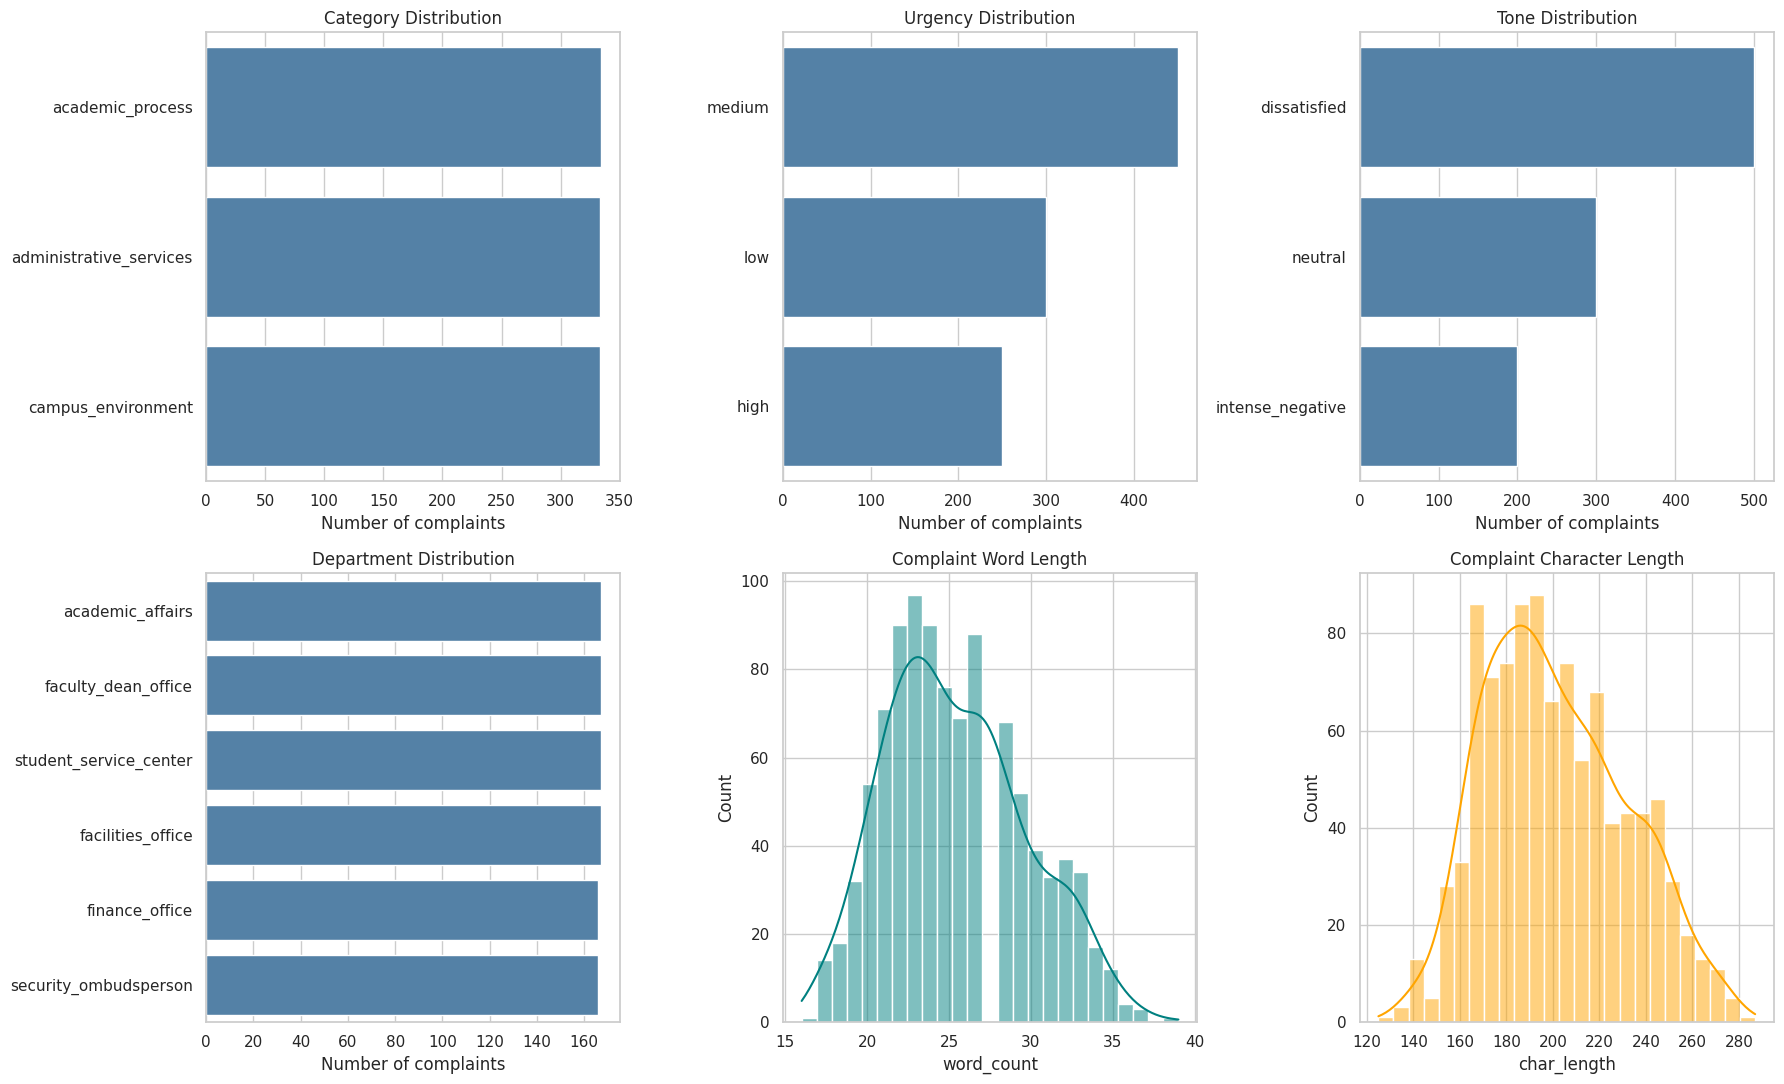

In [3]:

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, target in zip(axes.flat[:4], TARGETS):
    sns.countplot(
        data=df,
        y=target,
        order=df[target].value_counts().index,
        color="steelblue",
        ax=ax
    )
    ax.set_title(f"{target.capitalize()} Distribution")
    ax.set_xlabel("Number of complaints")
    ax.set_ylabel("")

sns.histplot(
    df["word_count"],
    bins=25,
    kde=True,
    color="teal",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Complaint Word Length")

sns.histplot(
    df["char_length"],
    bins=25,
    kde=True,
    color="orange",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Complaint Character Length")

plt.tight_layout()
plt.savefig("dataset_eda.png", dpi=200, bbox_inches="tight")
plt.show()


In [4]:

import unicodedata
import re

def normalize_kazakh(text):
    text = unicodedata.normalize("NFC", str(text))
    text = re.sub(r"[\u200b-\u200d\ufeff]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["text_clean"] = df["text_kk"].apply(normalize_kazakh)

print("Normalized samples:")
display(df[["text_kk", "text_clean"]].head(5))

print("Unique normalized texts:", df["text_clean"].nunique())


Normalized samples:


,text_kk,text_clean
0,Соңғы уақытта пәнге тіркелу жүйесі өтінімді қа...,Соңғы уақытта пәнге тіркелу жүйесі өтінімді қа...
1,Емтихан кестесінде екі пән бір уақытқа қойылға...,Емтихан кестесінде екі пән бір уақытқа қойылға...
2,Неліктен аралық бақылау бағасы жүйеде қате көр...,Неліктен аралық бақылау бағасы жүйеде қате көр...
3,Қайта қарағанымда силлабус семестр басталса да...,Қайта қарағанымда силлабус семестр басталса да...
4,Курстық жұмыс тапсыру мерзімі жүйеде ескертусі...,Курстық жұмыс тапсыру мерзімі жүйеде ескертусі...


Unique normalized texts: 1000


In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

similarity_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=1
)

X_similarity = similarity_vectorizer.fit_transform(df["text_clean"])
similarity = cosine_similarity(X_similarity)

np.fill_diagonal(similarity, 0)

pairs = []

for i in range(len(df)):
    for j in range(i + 1, len(df)):
        if similarity[i, j] >= 0.85:
            pairs.append((i, j, round(float(similarity[i, j]), 3)))

pairs.sort(key=lambda x: x[2], reverse=True)

print("Highly similar pairs:", len(pairs))

for i, j, score in pairs[:5]:
    print(f"\nSimilarity: {score}")
    print("A:", df.iloc[i]["text_clean"])
    print("B:", df.iloc[j]["text_clean"])


Highly similar pairs: 20

Similarity: 0.873
A: Бөліп төлеу өтінішіне жауап кешікті, ал түсіндіру берілмеді. Сондықтан келесі төлем мерзімі жақындап қалды. Бұл өрескел жағдайды созбай тоқтатып, нәтижесін ашық хабарлауды талап етемін.
B: Бөліп төлеу өтінішіне жауап кешікті. Салдары: келесі төлем мерзімі жақындап қалды. Бұл өрескел жағдайды созбай тоқтатып, нәтижесін ашық хабарлауды талап етемін.

Similarity: 0.872
A: Қызмет көрсету уақыты сайтта дұрыс көрсетілмеген, ал түсіндіру берілмеді. Сондықтан босқа келіп, өтініш бере алмай қайттым. Бірнеше рет тексерсем де өзгеріс жоқ, жауапты бөлім шара қабылдасын.
B: Неліктен қызмет көрсету уақыты сайтта дұрыс көрсетілмеген? Соның кесірінен босқа келіп, өтініш бере алмай қайттым. Бірнеше рет тексерсем де өзгеріс жоқ, жауапты бөлім шара қабылдасын.

Similarity: 0.868
A: Қызметті пайдалану кезінде қауіпсіздік қызметіне берілген арыз құпия сақталмады; соның салдарынан қайта қысым көруден қауіптенемін. Қалыпты қызмет ала алмай жүрмін, мәселені енді 

In [6]:

from sklearn.model_selection import train_test_split

strata = df["category"].astype(str) + "_" + df["urgency"].astype(str)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=strata
)

temp_strata = (
    temp_df["category"].astype(str)
    + "_"
    + temp_df["urgency"].astype(str)
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_strata
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("\nDatasets saved successfully!")


Train: 700
Validation: 150
Test: 150

Datasets saved successfully!


In [7]:

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Compare texts across dataset splits
splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name_a, name_b in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    A = similarity_vectorizer.transform(
        splits[name_a]["text_clean"]
    )
    B = similarity_vectorizer.transform(
        splits[name_b]["text_clean"]
    )

    scores = cosine_similarity(A, B)

    print(f"\n{name_a} vs {name_b}")
    print("Maximum similarity:", round(scores.max(), 4))
    print("Pairs >= 0.85:", int((scores >= 0.85).sum()))
    print("Pairs >= 0.80:", int((scores >= 0.80).sum()))



Train vs Validation
Maximum similarity: 0.8735
Pairs >= 0.85: 6
Pairs >= 0.80: 20

Train vs Test
Maximum similarity: 0.8723
Pairs >= 0.85: 5
Pairs >= 0.80: 24

Validation vs Test
Maximum similarity: 0.8601
Pairs >= 0.85: 1
Pairs >= 0.80: 6


In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import joblib

TARGETS = ["category", "urgency", "tone", "department"]
C_VALUES = [0.01, 0.1, 1, 10]

svm_models = {}
svm_results = []
svm_val_predictions = {}

for target in TARGETS:
    print(f"\nTraining SVM for: {target}")

    best_score = -1
    best_model = None
    best_c = None

    for c in C_VALUES:
        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(2, 5),
                min_df=2,
                sublinear_tf=True
            )),
            ("svm", LinearSVC(
                C=c,
                class_weight="balanced",
                random_state=42,
                max_iter=5000
            ))
        ])

        pipeline.fit(train_df["text_clean"], train_df[target])
        preds = pipeline.predict(val_df["text_clean"])

        _, _, f1, _ = precision_recall_fscore_support(
            val_df[target],
            preds,
            average="macro",
            zero_division=0
        )

        if f1 > best_score:
            best_score = f1
            best_model = pipeline
            best_c = c

    preds = best_model.predict(val_df["text_clean"])

    precision, recall, f1, _ = precision_recall_fscore_support(
        val_df[target],
        preds,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(val_df[target], preds)

    svm_models[target] = best_model
    svm_val_predictions[target] = preds

    svm_results.append({
        "Task": target,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro-F1": f1,
        "Best C": best_c
    })

    joblib.dump(best_model, f"svm_{target}.joblib")

    print(f"Best C: {best_c}")
    print(f"Validation Macro-F1: {f1:.4f}")

svm_results_df = pd.DataFrame(svm_results)

print("\nFINAL SVM RESULTS")
display(svm_results_df.round(4))

svm_results_df.to_csv("svm_validation_results.csv", index=False)



Training SVM for: category
Best C: 1
Validation Macro-F1: 0.9867

Training SVM for: urgency
Best C: 10
Validation Macro-F1: 0.9861

Training SVM for: tone
Best C: 1
Validation Macro-F1: 1.0000

Training SVM for: department
Best C: 1
Validation Macro-F1: 0.9588

FINAL SVM RESULTS


,Task,Accuracy,Precision,Recall,Macro-F1,Best C
0,category,0.9867,0.9867,0.9867,0.9867,1
1,urgency,0.9867,0.9861,0.9861,0.9861,10
2,tone,1.0000,1.0000,1.0000,1.0000,1
3,department,0.9600,0.9580,0.9601,0.9588,1


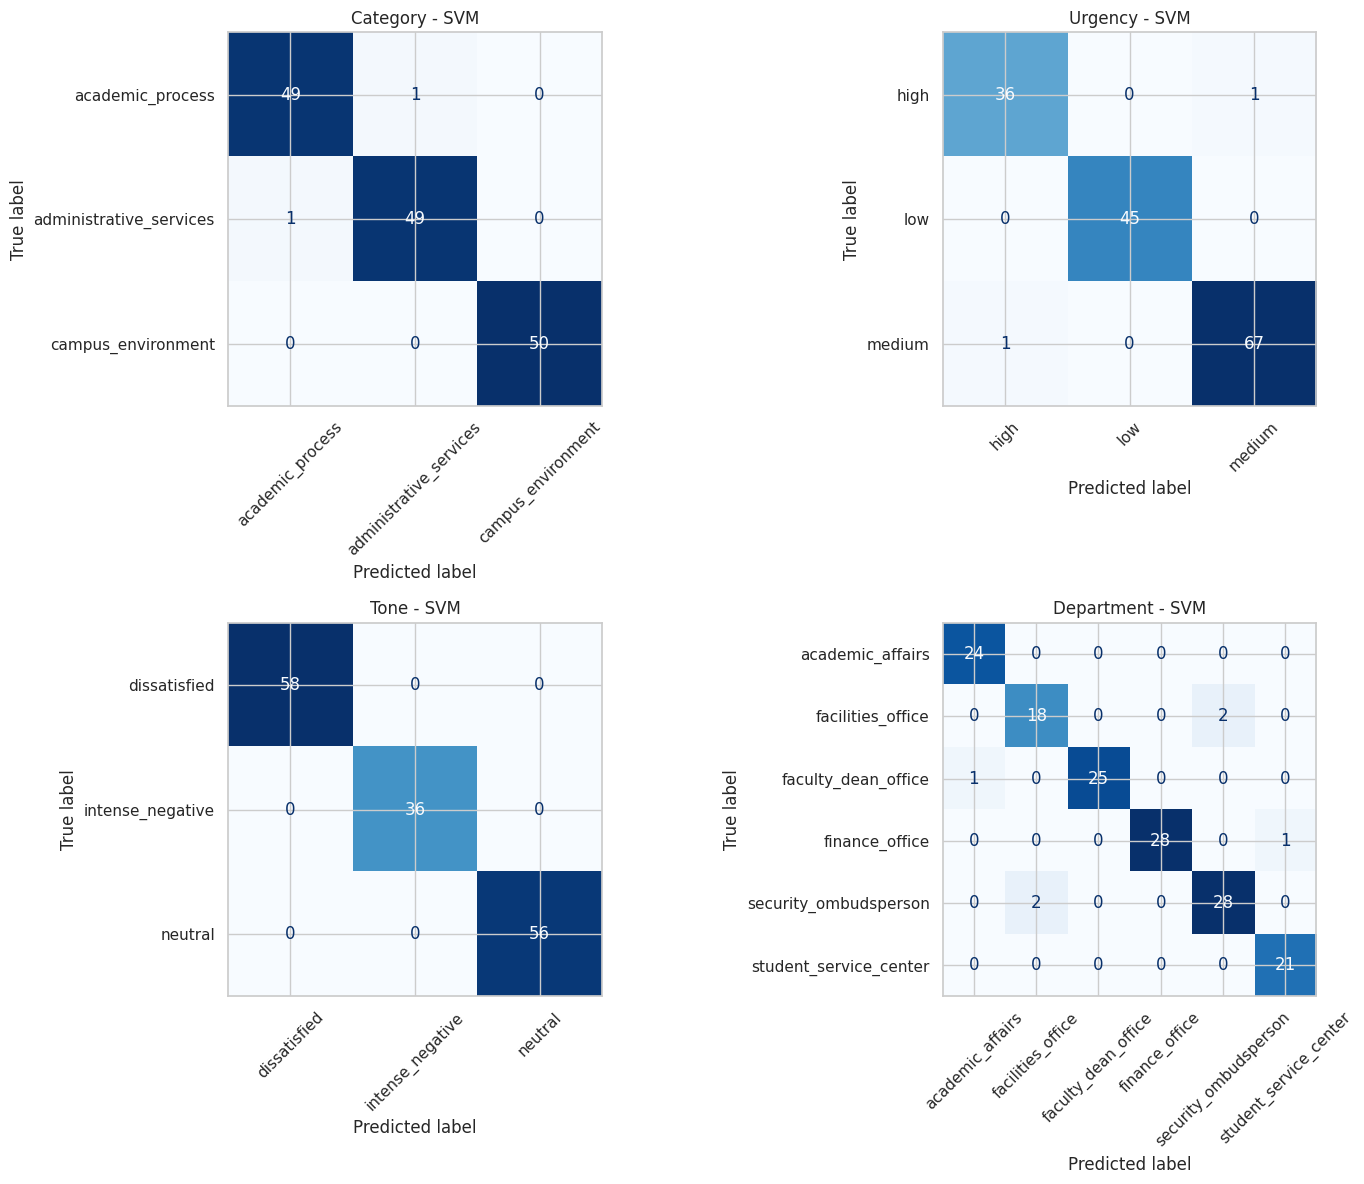

In [9]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, target in zip(axes.flatten(), TARGETS):
    model = svm_models[target]

    preds = model.predict(val_df["text_clean"])
    labels = model.classes_

    cm = confusion_matrix(
        val_df[target],
        preds,
        labels=labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(f"{target.capitalize()} - SVM")

plt.tight_layout()
plt.savefig("svm_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:

for target in TARGETS:
    preds = svm_val_predictions[target]

    errors = val_df.loc[
        val_df[target].to_numpy() != preds,
        ["text_clean", target]
    ].copy()

    errors["predicted"] = preds[
        val_df[target].to_numpy() != preds
    ]

    print(f"\n{target.upper()} - Errors: {len(errors)}")
    display(errors.head(5))

    errors.to_csv(f"svm_errors_{target}.csv", index=False)



CATEGORY - Errors: 2


,text_clean,category,predicted
25,Хабарлағым келетіні: оқуға қайта қабылдану шар...,academic_process,administrative_services
82,"Назарларыңызға: грант иесі болсам да, менен оқ...",administrative_services,academic_process



URGENCY - Errors: 2


,text_clean,urgency,predicted
56,Қайта қарағанымда қорғауға жіберу құжаттарының...,medium,high
82,"Назарларыңызға: грант иесі болсам да, менен оқ...",high,medium



TONE - Errors: 0


,text_clean,tone,predicted



DEPARTMENT - Errors: 6


,text_clean,department,predicted
29,Назарларыңызға: кітапханадағы принтер айлап жө...,facilities_office,security_ombudsperson
34,Хабарлағым келетіні: кеш төлегенім үшін айыппұ...,finance_office,student_service_center
77,Хабарлағым келетіні: топ старостасын сайлау тә...,faculty_dean_office,academic_affairs
95,"Асхана мәзірінде вегетариан тағамы мүлде жоқ, ...",facilities_office,security_ombudsperson
119,Апаттық шығу есігі құлыптаулы тұр. Осының салд...,security_ombudsperson,facilities_office


In [11]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

TARGETS = ["category", "urgency", "tone", "department"]
MAX_LEN = 80
BATCH_SIZE = 32

# Build vocabulary using training data only
counter = Counter()
for text in train_df["text_clean"]:
    counter.update(str(text).lower().split())

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, freq in counter.items():
    if freq >= 2:
        vocab[word] = len(vocab)

label_maps = {
    task: {
        label: i for i, label in enumerate(sorted(train_df[task].unique()))
    }
    for task in TARGETS
}

def encode_text(text):
    tokens = str(text).lower().split()[:MAX_LEN]
    ids = [vocab.get(t, 1) for t in tokens]
    return ids + [0] * (MAX_LEN - len(ids))

class ComplaintDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["text_clean"].tolist()
        self.labels = {
            task: dataframe[task].map(label_maps[task]).tolist()
            for task in TARGETS
        }
        for task in TARGETS:
            assert not pd.isna(self.labels[task]).any()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return (
            torch.tensor(encode_text(self.texts[idx]), dtype=torch.long),
            torch.tensor(
                [self.labels[t][idx] for t in TARGETS],
                dtype=torch.long
            )
        )

train_loader = DataLoader(
    ComplaintDataset(train_df), batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    ComplaintDataset(val_df), batch_size=BATCH_SIZE
)

class MultiTaskBiLSTM(nn.Module):
    def __init__(self, vocab_size, num_classes, embed_dim=128, hidden=128):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embed_dim, hidden, batch_first=True,
            bidirectional=True
        )
        self.attention = nn.Linear(hidden * 2, 1)
        self.dropout = nn.Dropout(0.4)
        self.heads = nn.ModuleList([
            nn.Linear(hidden * 2, n) for n in num_classes
        ])

    def forward(self, x):
        mask = x != 0
        embedded = self.embedding(x)
        outputs, _ = self.lstm(embedded)

        scores = self.attention(outputs).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=1)

        pooled = torch.sum(outputs * weights.unsqueeze(-1), dim=1)
        pooled = self.dropout(pooled)

        return [head(pooled) for head in self.heads]

model = MultiTaskBiLSTM(
    vocab_size=len(vocab),
    num_classes=[len(label_maps[t]) for t in TARGETS]
).to(device)

print("Vocabulary size:", len(vocab))
print("Parameters:", sum(p.numel() for p in model.parameters()))


Device: cuda
Vocabulary size: 1046
Parameters: 402192


Epoch 01 | Train Loss: 4.8824 | Val Loss: 4.6655 | Mean Macro-F1: 0.3786
Epoch 02 | Train Loss: 4.1214 | Val Loss: 3.7248 | Mean Macro-F1: 0.6550
Epoch 03 | Train Loss: 3.1245 | Val Loss: 2.9385 | Mean Macro-F1: 0.7102
Epoch 04 | Train Loss: 2.3139 | Val Loss: 2.2180 | Mean Macro-F1: 0.7784
Epoch 05 | Train Loss: 1.5814 | Val Loss: 1.7165 | Mean Macro-F1: 0.8447
Epoch 06 | Train Loss: 1.0461 | Val Loss: 1.1821 | Mean Macro-F1: 0.8822
Epoch 07 | Train Loss: 0.7147 | Val Loss: 1.0645 | Mean Macro-F1: 0.8969
Epoch 08 | Train Loss: 0.4798 | Val Loss: 0.7995 | Mean Macro-F1: 0.9371
Epoch 09 | Train Loss: 0.3008 | Val Loss: 0.5698 | Mean Macro-F1: 0.9513
Epoch 10 | Train Loss: 0.2181 | Val Loss: 0.5618 | Mean Macro-F1: 0.9492
Epoch 11 | Train Loss: 0.1514 | Val Loss: 0.6666 | Mean Macro-F1: 0.9566
Epoch 12 | Train Loss: 0.0882 | Val Loss: 0.5515 | Mean Macro-F1: 0.9591
Epoch 13 | Train Loss: 0.0538 | Val Loss: 0.6076 | Mean Macro-F1: 0.9634
Epoch 14 | Train Loss: 0.0461 | Val Loss: 0.5856 | 

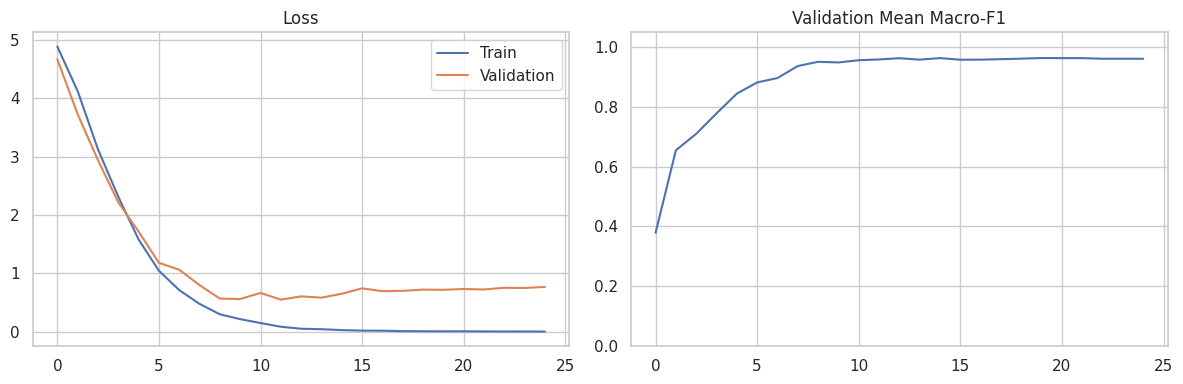

In [12]:

import copy
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()

history = {"train_loss": [], "val_loss": [], "val_f1": []}
best_f1 = -1
best_state = None
patience = 5
no_improve = 0

def evaluate(model, loader):
    model.eval()
    all_true = [[] for _ in TARGETS]
    all_pred = [[] for _ in TARGETS]
    total_loss = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = sum(
                criterion(outputs[i], y[:, i])
                for i in range(len(TARGETS))
            )
            total_loss += loss.item() * len(x)

            for i in range(len(TARGETS)):
                all_true[i].extend(y[:, i].cpu().tolist())
                all_pred[i].extend(outputs[i].argmax(1).cpu().tolist())

    f1s = [
        f1_score(all_true[i], all_pred[i], average="macro",
                 labels=list(range(len(label_maps[TARGETS[i]]))),
                 zero_division=0)
        for i in range(len(TARGETS))
    ]
    return total_loss / len(loader.dataset), f1s, all_true, all_pred

for epoch in range(25):
    model.train()
    train_loss = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        outputs = model(x)
        loss = sum(
            criterion(outputs[i], y[:, i])
            for i in range(len(TARGETS))
        )

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item() * len(x)

    train_loss /= len(train_loader.dataset)
    val_loss, f1s, _, _ = evaluate(model, val_loader)
    mean_f1 = np.mean(f1s)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(mean_f1)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Mean Macro-F1: {mean_f1:.4f}"
    )

    if mean_f1 > best_f1 + 1e-4:
        best_f1 = mean_f1
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= patience:
        print("Early stopping triggered")
        break

model.load_state_dict(best_state)
torch.save(model.state_dict(), "multitask_bilstm_best.pt")

_, f1s, all_true, all_pred = evaluate(model, val_loader)

print("\nFINAL BiLSTM VALIDATION RESULTS")
for i, task in enumerate(TARGETS):
    print(f"{task}: Macro-F1 = {f1s[i]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(history["val_f1"])
axes[1].set_title("Validation Mean Macro-F1")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


In [13]:

!pip -q install transformers sentencepiece

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "FacebookAI/xlm-roberta-base"
MAX_LENGTH = 96
BATCH_SIZE = 8

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TransformerDataset(Dataset):
    def __init__(self, dataframe):
        self.encodings = tokenizer(
            dataframe["text_clean"].tolist(),
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        self.labels = torch.tensor([
            [label_maps[t][row[t]] for t in TARGETS]
            for _, row in dataframe.iterrows()
        ], dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx]
        }

xlm_train_loader = DataLoader(
    TransformerDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)
xlm_val_loader = DataLoader(
    TransformerDataset(val_df),
    batch_size=BATCH_SIZE
)

class MultiTaskXLMR(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.2)

        self.heads = nn.ModuleList([
            nn.Linear(hidden_size, len(label_maps[t]))
            for t in TARGETS
        ])

    def forward(self, input_ids, attention_mask):
        output = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state

        mask = attention_mask.unsqueeze(-1)
        pooled = (output * mask).sum(1) / mask.sum(1).clamp(min=1)
        pooled = self.dropout(pooled)

        return [head(pooled) for head in self.heads]

xlm_model = MultiTaskXLMR().to(device)

print("Parameters:", sum(
    p.numel() for p in xlm_model.parameters()
))


Device: cuda


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Parameters: 278055183


/tmp/ipykernel_5165/453050768.py:107: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1 | Train Loss: 5.0698 | Val Loss: 4.7655 | Mean F1: 0.4226
Epoch 2 | Train Loss: 3.5049 | Val Loss: 2.5179 | Mean F1: 0.7683
Epoch 3 | Train Loss: 1.9500 | Val Loss: 1.5999 | Mean F1: 0.8785
Epoch 4 | Train Loss: 1.2793 | Val Loss: 1.1161 | Mean F1: 0.9228
Epoch 5 | Train Loss: 0.9890 | Val Loss: 1.0434 | Mean F1: 0.9197

FINAL XLM-RoBERTa VALIDATION RESULTS
category: 0.9667
urgency: 0.9195
tone: 0.9533
department: 0.8517


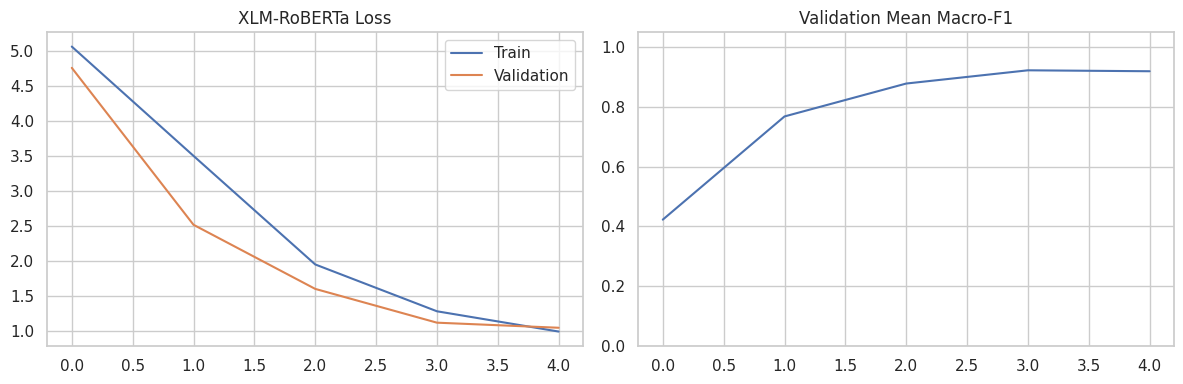

In [14]:

from sklearn.metrics import f1_score
from transformers import get_linear_schedule_with_warmup
import numpy as np
import matplotlib.pyplot as plt

EPOCHS = 5
ACCUM_STEPS = 2

optimizer = torch.optim.AdamW(
    xlm_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)
criterion = nn.CrossEntropyLoss()

total_steps = (
    (len(xlm_train_loader) + ACCUM_STEPS - 1)
    // ACCUM_STEPS
) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def evaluate_xlm():
    xlm_model.eval()
    all_true = [[] for _ in TARGETS]
    all_pred = [[] for _ in TARGETS]
    total_loss = 0

    with torch.no_grad():
        for batch in xlm_val_loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast("cuda", enabled=use_amp):
                outputs = xlm_model(ids, mask)
                loss = sum(
                    criterion(outputs[i], labels[:, i])
                    for i in range(len(TARGETS))
                )

            total_loss += loss.item() * len(ids)

            for i in range(len(TARGETS)):
                all_true[i].extend(labels[:, i].cpu().tolist())
                all_pred[i].extend(
                    outputs[i].argmax(1).cpu().tolist()
                )

    scores = [
        f1_score(
            all_true[i], all_pred[i],
            average="macro", zero_division=0,
            labels=list(range(len(label_maps[TARGETS[i]])))
        )
        for i in range(len(TARGETS))
    ]

    return total_loss / len(xlm_val_loader.dataset), scores

xlm_history = {"train_loss": [], "val_loss": [], "val_f1": []}
best_f1 = -1
no_improve = 0

for epoch in range(EPOCHS):
    xlm_model.train()
    optimizer.zero_grad()
    running_loss = 0

    for step, batch in enumerate(xlm_train_loader):
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.autocast("cuda", enabled=use_amp):
            outputs = xlm_model(ids, mask)
            loss = sum(
                criterion(outputs[i], labels[:, i])
                for i in range(len(TARGETS))
            )

        running_loss += loss.item() * len(ids)

        # Handle the final partial accumulation batch
        remaining = len(xlm_train_loader) - (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS
        divisor = min(ACCUM_STEPS, remaining)

        scaler.scale(loss / divisor).backward()

        if (
            (step + 1) % ACCUM_STEPS == 0
            or (step + 1) == len(xlm_train_loader)
        ):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(xlm_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

    train_loss = running_loss / len(xlm_train_loader.dataset)
    val_loss, scores = evaluate_xlm()
    mean_f1 = float(np.mean(scores))

    xlm_history["train_loss"].append(train_loss)
    xlm_history["val_loss"].append(val_loss)
    xlm_history["val_f1"].append(mean_f1)

    print(
        f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | Mean F1: {mean_f1:.4f}"
    )

    if mean_f1 > best_f1 + 1e-4:
        best_f1 = mean_f1
        no_improve = 0
        torch.save(xlm_model.state_dict(), "xlmr_multitask_best.pt")
        tokenizer.save_pretrained("xlmr_tokenizer")
    else:
        no_improve += 1

    if no_improve >= 2:
        print("Early stopping!")
        break

xlm_model.load_state_dict(
    torch.load(
        "xlmr_multitask_best.pt",
        map_location=device,
        weights_only=True
    )
)

_, final_scores = evaluate_xlm()

print("\nFINAL XLM-RoBERTa VALIDATION RESULTS")
for task, score in zip(TARGETS, final_scores):
    print(f"{task}: {score:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(xlm_history["train_loss"], label="Train")
axes[0].plot(xlm_history["val_loss"], label="Validation")
axes[0].set_title("XLM-RoBERTa Loss")
axes[0].legend()

axes[1].plot(xlm_history["val_f1"])
axes[1].set_title("Validation Mean Macro-F1")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


In [15]:

import gc
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# Free GPU memory from XLM-RoBERTa
for name in ["xlm_model", "optimizer", "scheduler", "scaler"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

KAZ_MODEL_NAME = "kz-transformers/kaz-roberta-conversational"
MAX_LENGTH = 96
BATCH_SIZE = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

kaz_tokenizer = AutoTokenizer.from_pretrained(KAZ_MODEL_NAME)

class KazComplaintDataset(Dataset):
    def __init__(self, dataframe):
        self.encodings = kaz_tokenizer(
            dataframe["text_clean"].tolist(),
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        self.labels = torch.tensor([
            [label_maps[t][row[t]] for t in TARGETS]
            for _, row in dataframe.iterrows()
        ], dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx]
        }

kaz_train_loader = DataLoader(
    KazComplaintDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)

kaz_val_loader = DataLoader(
    KazComplaintDataset(val_df),
    batch_size=BATCH_SIZE
)

class MultiTaskKazRoBERTa(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(KAZ_MODEL_NAME)
        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(0.2)

        self.heads = nn.ModuleList([
            nn.Linear(hidden_size, len(label_maps[t]))
            for t in TARGETS
        ])

    def forward(self, input_ids, attention_mask):
        hidden = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state

        mask = attention_mask.unsqueeze(-1)

        pooled = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        pooled = self.dropout(pooled)

        return [head(pooled) for head in self.heads]

kaz_model = MultiTaskKazRoBERTa().to(device)

print("Parameters:", sum(
    p.numel() for p in kaz_model.parameters()
))


Device: cuda


config.json: reconstructing file:   0%|          |  0.00B /   636B            

config.json: downloading bytes:           |  0.00B            

vocab.json: reconstructing file:   0%|          |  0.00B / 1.69MB            

vocab.json: downloading bytes:           |  0.00B            

merges.txt: reconstructing file:   0%|          |  0.00B / 1.33MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: kz-transformers/kaz-roberta-conversational
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 83462415


Epoch 01/8 | Train Loss: 4.8506 | Val Loss: 4.5090 | Mean Macro-F1: 0.3753
Epoch 02/8 | Train Loss: 3.8111 | Val Loss: 2.9449 | Mean Macro-F1: 0.7851
Epoch 03/8 | Train Loss: 2.3478 | Val Loss: 1.7181 | Mean Macro-F1: 0.8809
Epoch 04/8 | Train Loss: 1.4106 | Val Loss: 1.1875 | Mean Macro-F1: 0.9205
Epoch 05/8 | Train Loss: 0.9635 | Val Loss: 0.8880 | Mean Macro-F1: 0.9298
Epoch 06/8 | Train Loss: 0.6842 | Val Loss: 0.6974 | Mean Macro-F1: 0.9573
Epoch 07/8 | Train Loss: 0.5319 | Val Loss: 0.6002 | Mean Macro-F1: 0.9553
Epoch 08/8 | Train Loss: 0.4585 | Val Loss: 0.5737 | Mean Macro-F1: 0.9624

FINAL KazRoBERTa VALIDATION RESULTS


,Task,Accuracy,Macro-F1
0,category,0.9800,0.9801
1,urgency,0.9733,0.9731
2,tone,0.9933,0.9924
3,department,0.9067,0.9040


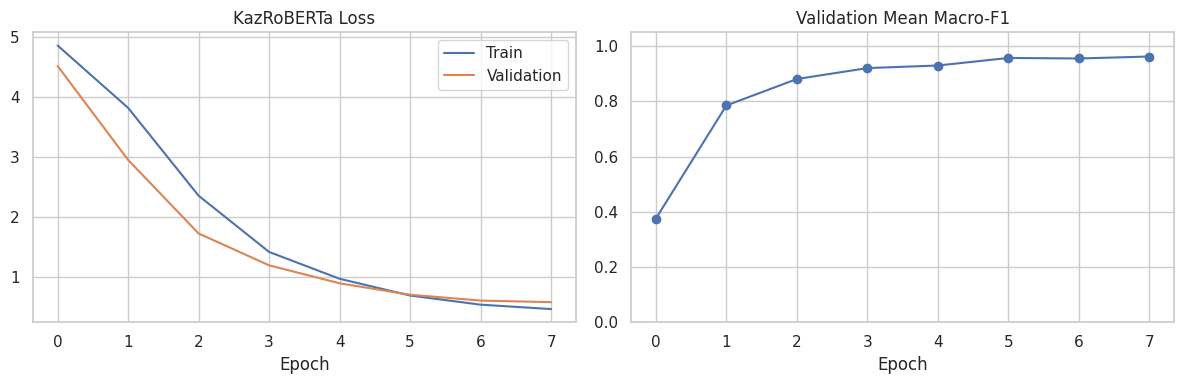

In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score
from transformers import get_linear_schedule_with_warmup

EPOCHS = 8
PATIENCE = 3
ACCUM_STEPS = 2

optimizer = torch.optim.AdamW(
    kaz_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

steps_per_epoch = (
    len(kaz_train_loader) + ACCUM_STEPS - 1
) // ACCUM_STEPS

total_steps = steps_per_epoch * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def evaluate_kaz():
    kaz_model.eval()

    truths = [[] for _ in TARGETS]
    predictions = [[] for _ in TARGETS]
    total_loss = 0

    with torch.no_grad():
        for batch in kaz_val_loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast("cuda", enabled=use_amp):
                outputs = kaz_model(ids, mask)

                loss = sum(
                    criterion(outputs[i], labels[:, i])
                    for i in range(len(TARGETS))
                )

            total_loss += loss.item() * len(ids)

            for i in range(len(TARGETS)):
                truths[i].extend(labels[:, i].cpu().tolist())
                predictions[i].extend(
                    outputs[i].argmax(dim=1).cpu().tolist()
                )

    scores = [
        f1_score(
            truths[i],
            predictions[i],
            average="macro",
            labels=list(range(len(label_maps[TARGETS[i]]))),
            zero_division=0
        )
        for i in range(len(TARGETS))
    ]

    return total_loss / len(kaz_val_loader.dataset), scores, truths, predictions

kaz_history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": []
}

best_f1 = -1
no_improve = 0

for epoch in range(EPOCHS):
    kaz_model.train()
    optimizer.zero_grad()
    running_loss = 0

    for step, batch in enumerate(kaz_train_loader):
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.autocast("cuda", enabled=use_amp):
            outputs = kaz_model(ids, mask)

            loss = sum(
                criterion(outputs[i], labels[:, i])
                for i in range(len(TARGETS))
            )

        running_loss += loss.item() * len(ids)

        remaining = len(kaz_train_loader) - (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        divisor = min(ACCUM_STEPS, remaining)

        scaler.scale(loss / divisor).backward()

        if (
            (step + 1) % ACCUM_STEPS == 0
            or step + 1 == len(kaz_train_loader)
        ):
            scaler.unscale_(optimizer)

            nn.utils.clip_grad_norm_(
                kaz_model.parameters(), 1.0
            )

            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()

            # Skip scheduler step if AMP skipped optimizer update
            if scaler.get_scale() >= old_scale:
                scheduler.step()

            optimizer.zero_grad()

    train_loss = running_loss / len(kaz_train_loader.dataset)

    val_loss, scores, _, _ = evaluate_kaz()
    mean_f1 = float(np.mean(scores))

    kaz_history["train_loss"].append(train_loss)
    kaz_history["val_loss"].append(val_loss)
    kaz_history["val_f1"].append(mean_f1)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Mean Macro-F1: {mean_f1:.4f}",
        flush=True
    )

    if mean_f1 > best_f1 + 1e-4:
        best_f1 = mean_f1
        no_improve = 0

        torch.save(
            kaz_model.state_dict(),
            "kazroberta_multitask_best.pt"
        )
        kaz_tokenizer.save_pretrained("kazroberta_tokenizer")

    else:
        no_improve += 1

    if no_improve >= PATIENCE:
        print("Early stopping triggered!")
        break

# Restore best checkpoint
kaz_model.load_state_dict(
    torch.load(
        "kazroberta_multitask_best.pt",
        map_location=device,
        weights_only=True
    )
)

val_loss, scores, truths, predictions = evaluate_kaz()

print("\nFINAL KazRoBERTa VALIDATION RESULTS")

kaz_results = []

for i, task in enumerate(TARGETS):
    accuracy = accuracy_score(truths[i], predictions[i])

    kaz_results.append({
        "Task": task,
        "Accuracy": accuracy,
        "Macro-F1": scores[i]
    })

kaz_results_df = pd.DataFrame(kaz_results)
display(kaz_results_df.round(4))

kaz_results_df.to_csv(
    "kazroberta_validation_results.csv",
    index=False
)

# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(kaz_history["train_loss"], label="Train")
axes[0].plot(kaz_history["val_loss"], label="Validation")
axes[0].set_title("KazRoBERTa Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(kaz_history["val_f1"], marker="o")
axes[1].set_title("Validation Mean Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig("kazroberta_training.png", dpi=200)
plt.show()


In [17]:

import os
import torch
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

TARGETS = ["category", "urgency", "tone", "department"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

files_to_check = [
    "multitask_bilstm_best.pt",
    "xlmr_multitask_best.pt",
    "kazroberta_multitask_best.pt"
] + [f"svm_{t}.joblib" for t in TARGETS]

print("CHECKPOINT STATUS")
for path in files_to_check:
    print(f"{path}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

# Restore SVM; use the C values selected on validation earlier
best_c_values = {
    "category": 1,
    "urgency": 10,
    "tone": 1,
    "department": 1
}

svm_models = {}

for task in TARGETS:
    path = f"svm_{task}.joblib"

    if os.path.exists(path):
        svm_models[task] = joblib.load(path)
    else:
        print(f"Rebuilding SVM: {task}")

        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(2, 5),
                min_df=2,
                sublinear_tf=True
            )),
            ("svm", LinearSVC(
                C=best_c_values[task],
                class_weight="balanced",
                random_state=42,
                max_iter=5000
            ))
        ])

        pipeline.fit(train_df["text_clean"], train_df[task])
        svm_models[task] = pipeline
        joblib.dump(pipeline, path)

print("\nSVM ready!")
print("Device:", device)


CHECKPOINT STATUS
multitask_bilstm_best.pt: FOUND
xlmr_multitask_best.pt: FOUND
kazroberta_multitask_best.pt: FOUND
svm_category.joblib: FOUND
svm_urgency.joblib: FOUND
svm_tone.joblib: FOUND
svm_department.joblib: FOUND

SVM ready!
Device: cuda


SVM evaluated
BiLSTM evaluated
KazRoBERTa evaluated


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XLM-RoBERTa evaluated


,Model,Task,Accuracy,Macro-F1,Errors
0,Linear SVM,category,0.9867,0.9867,2
1,Linear SVM,urgency,0.9733,0.9722,4
2,Linear SVM,tone,1.0000,1.0000,0
3,Linear SVM,department,0.9333,0.9334,10
4,BiLSTM,category,0.9733,0.9733,4
5,BiLSTM,urgency,0.9800,0.9790,3
6,BiLSTM,tone,1.0000,1.0000,0
7,BiLSTM,department,0.8667,0.8642,20
8,KazRoBERTa,category,0.9933,0.9933,1
9,KazRoBERTa,urgency,0.9533,0.9510,7



FINAL TEST COMPARISON


Task,category,department,tone,urgency,Mean Macro-F1
Model,,,,,
Linear SVM,0.9867,0.9334,1.0000,0.9722,0.9731
KazRoBERTa,0.9933,0.9128,0.9844,0.9510,0.9604
BiLSTM,0.9733,0.8642,1.0000,0.9790,0.9541
XLM-RoBERTa,0.9798,0.9000,0.9681,0.9313,0.9448


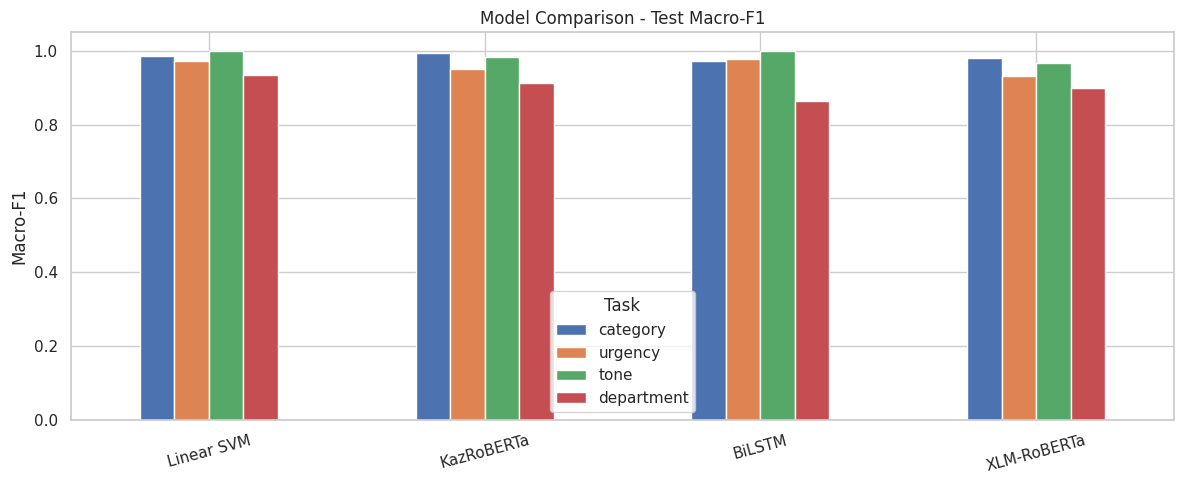

In [18]:

import gc
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)
from transformers import AutoTokenizer

results = []
test_predictions = {}

def record_results(model_name, predictions):
    test_predictions[model_name] = predictions

    for task in TARGETS:
        true = test_df[task].to_numpy()
        pred = np.asarray(predictions[task])

        results.append({
            "Model": model_name,
            "Task": task,
            "Accuracy": accuracy_score(true, pred),
            "Macro-F1": f1_score(
                true, pred, average="macro", zero_division=0
            ),
            "Errors": int(np.sum(true != pred))
        })

def predict_transformer(net, tok, texts):
    net.eval()
    output = {task: [] for task in TARGETS}

    with torch.inference_mode():
        for start in range(0, len(texts), 16):
            batch = tok(
                texts[start:start + 16],
                padding=True,
                truncation=True,
                max_length=96,
                return_tensors="pt"
            ).to(device)

            logits = net(
                batch["input_ids"],
                batch["attention_mask"]
            )

            for i, task in enumerate(TARGETS):
                indices = logits[i].argmax(dim=1).cpu().tolist()
                inverse = {v: k for k, v in label_maps[task].items()}
                output[task].extend(inverse[j] for j in indices)

    return output

# 1. SVM
svm_preds = {
    task: svm_models[task].predict(test_df["text_clean"])
    for task in TARGETS
}
record_results("Linear SVM", svm_preds)
print("SVM evaluated")

# 2. BiLSTM
if os.path.exists("multitask_bilstm_best.pt"):
    bilstm = MultiTaskBiLSTM(
        vocab_size=len(vocab),
        num_classes=[len(label_maps[t]) for t in TARGETS]
    ).to(device)

    bilstm.load_state_dict(torch.load(
        "multitask_bilstm_best.pt",
        map_location=device,
        weights_only=True
    ))
    bilstm.eval()

    bilstm_preds = {task: [] for task in TARGETS}

    with torch.inference_mode():
        for start in range(0, len(test_df), 32):
            texts = test_df["text_clean"].iloc[start:start+32]
            x = torch.tensor(
                [encode_text(t) for t in texts],
                dtype=torch.long,
                device=device
            )

            logits = bilstm(x)

            for i, task in enumerate(TARGETS):
                inverse = {v: k for k, v in label_maps[task].items()}
                indices = logits[i].argmax(1).cpu().tolist()
                bilstm_preds[task].extend(inverse[j] for j in indices)

    record_results("BiLSTM", bilstm_preds)
    del bilstm
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    print("BiLSTM evaluated")
else:
    print("BiLSTM skipped: checkpoint missing")

texts = test_df["text_clean"].tolist()

# 3. KazRoBERTa
if os.path.exists("kazroberta_multitask_best.pt"):
    kaz_model.load_state_dict(torch.load(
        "kazroberta_multitask_best.pt",
        map_location=device,
        weights_only=True
    ))

    kaz_preds = predict_transformer(
        kaz_model, kaz_tokenizer, texts
    )
    record_results("KazRoBERTa", kaz_preds)
    print("KazRoBERTa evaluated")

    kaz_model.cpu()
    if device.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("KazRoBERTa skipped: checkpoint missing")

# 4. XLM-RoBERTa
if os.path.exists("xlmr_multitask_best.pt"):
    xlm_test_model = MultiTaskXLMR().to(device)

    xlm_test_model.load_state_dict(torch.load(
        "xlmr_multitask_best.pt",
        map_location=device,
        weights_only=True
    ))

    xlm_tok = AutoTokenizer.from_pretrained(
        "xlmr_tokenizer"
        if os.path.isdir("xlmr_tokenizer")
        else "FacebookAI/xlm-roberta-base"
    )

    xlm_preds = predict_transformer(
        xlm_test_model, xlm_tok, texts
    )

    record_results("XLM-RoBERTa", xlm_preds)
    del xlm_test_model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    print("XLM-RoBERTa evaluated")
else:
    print("XLM-RoBERTa skipped: checkpoint missing")

# Final comparison
results_df = pd.DataFrame(results)
display(results_df.round(4))

comparison = results_df.pivot(
    index="Model",
    columns="Task",
    values="Macro-F1"
)

comparison["Mean Macro-F1"] = comparison.mean(axis=1)
comparison = comparison.sort_values(
    "Mean Macro-F1", ascending=False
)

print("\nFINAL TEST COMPARISON")
display(comparison.round(4))

results_df.to_csv("final_test_results.csv", index=False)
comparison.to_csv("final_model_comparison.csv")

# Comparison chart
ax = comparison[TARGETS].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1.05)
)
ax.set_title("Model Comparison - Test Macro-F1")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=200)
plt.show()


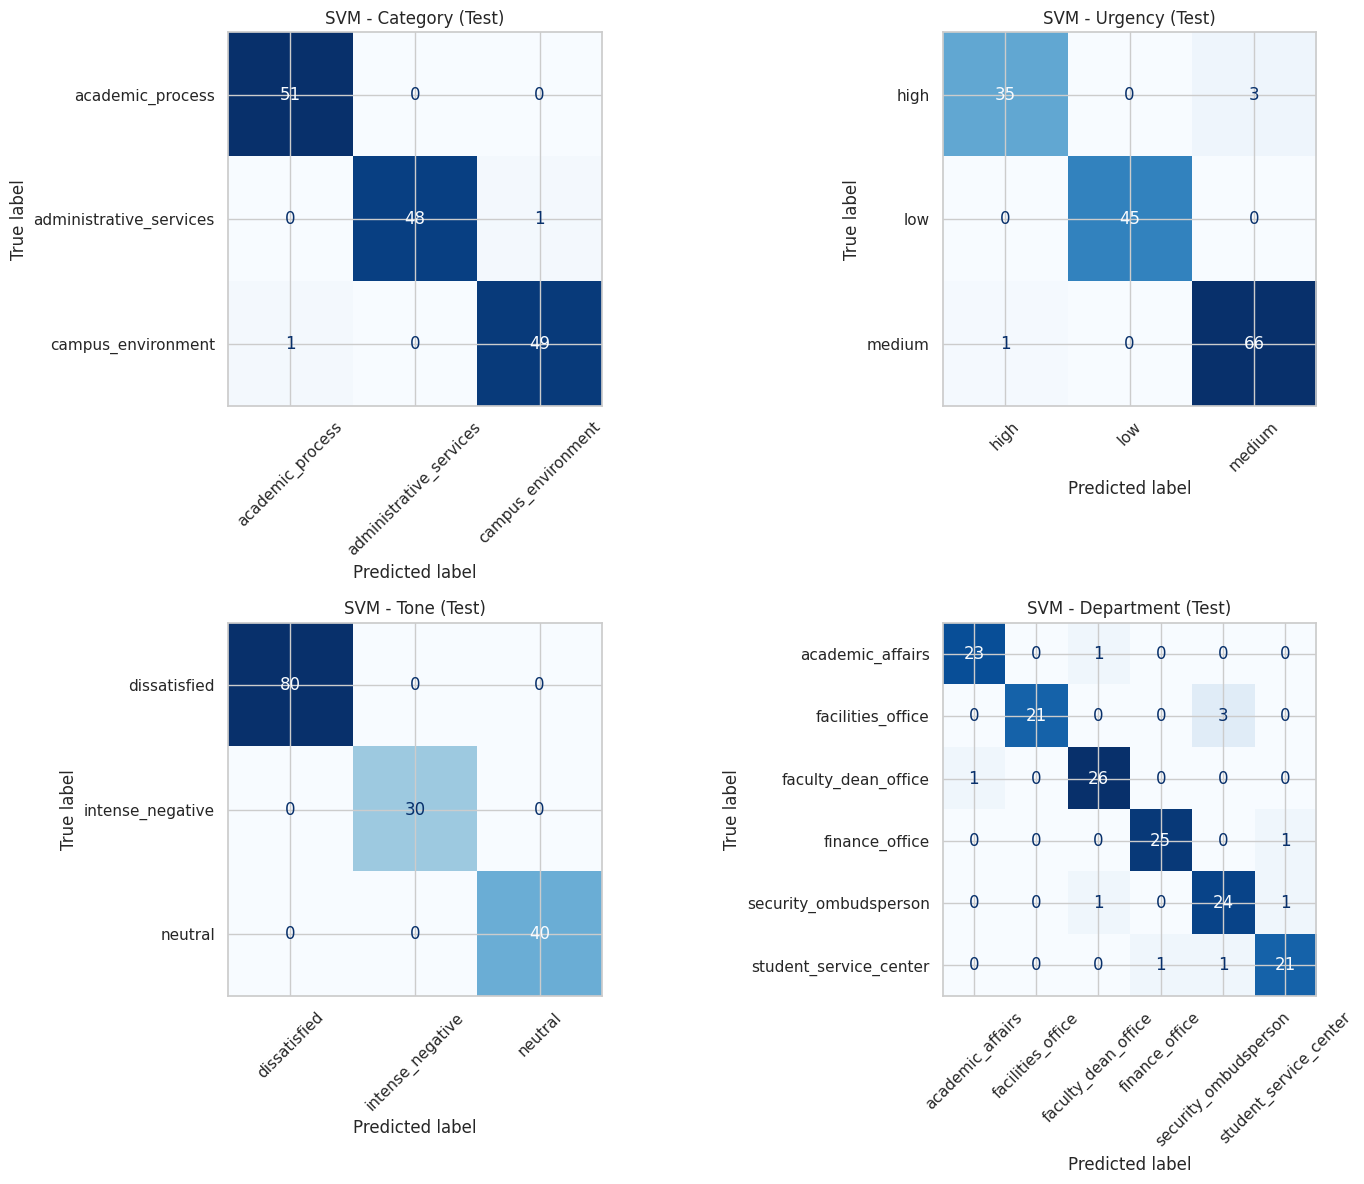


HIGH-URGENCY ERROR ANALYSIS
Linear SVM: 3 missed high-urgency complaints out of 38


,text_clean,urgency,predicted
70,Жатақханадағы кір жуғыш машиналардың жартысы і...,high,medium
85,Назарларыңызға: шағымымды растау үшін бейнежаз...,high,medium
89,Таңдау пәнінен бас тартуға өтініш беру формасы...,high,medium


BiLSTM: 3 missed high-urgency complaints out of 38


,text_clean,urgency,predicted
85,Назарларыңызға: шағымымды растау үшін бейнежаз...,high,medium
89,Таңдау пәнінен бас тартуға өтініш беру формасы...,high,medium
133,"Курстастар тобы бір студентті әдейі оқшаулап, ...",high,medium


KazRoBERTa: 5 missed high-urgency complaints out of 38


,text_clean,urgency,predicted
13,Студенттік жол жүру картасын рәсімдеу тоқтап қ...,high,medium
70,Жатақханадағы кір жуғыш машиналардың жартысы і...,high,medium
89,Таңдау пәнінен бас тартуға өтініш беру формасы...,high,medium


XLM-RoBERTa: 5 missed high-urgency complaints out of 38


,text_clean,urgency,predicted
70,Жатақханадағы кір жуғыш машиналардың жартысы і...,high,medium
85,Назарларыңызға: шағымымды растау үшін бейнежаз...,high,medium
89,Таңдау пәнінен бас тартуға өтініш беру формасы...,high,medium


In [19]:

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, task in zip(axes.flat, TARGETS):
    true = test_df[task].to_numpy()
    pred = np.asarray(test_predictions["Linear SVM"][task])

    labels = sorted(test_df[task].unique())
    cm = confusion_matrix(true, pred, labels=labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(f"SVM - {task.capitalize()} (Test)")

plt.tight_layout()
plt.savefig("final_confusion_matrices.png", dpi=200)
plt.show()

# High-urgency complaints incorrectly predicted as non-high
print("\nHIGH-URGENCY ERROR ANALYSIS")

for model_name, preds in test_predictions.items():
    urgent = test_df["urgency"].eq("high").to_numpy()
    predicted = np.asarray(preds["urgency"])

    missed = urgent & (predicted != "high")

    print(
        f"{model_name}: {missed.sum()} missed high-urgency "
        f"complaints out of {urgent.sum()}"
    )

    if missed.any():
        examples = test_df.loc[missed, ["text_clean", "urgency"]].copy()
        examples["predicted"] = predicted[missed]
        display(examples.head(3))


In [20]:

import torch
import pandas as pd
import numpy as np

kaz_model = kaz_model.to(device)
kaz_model.eval()

inverse_maps = {
    task: {v: k for k, v in label_maps[task].items()}
    for task in TARGETS
}

# Initial thresholds; tune only using validation data
CONFIDENCE_THRESHOLD = 0.60
URGENT_REVIEW_THRESHOLD = 0.30

SLA_HOURS = {
    "high": 4,
    "medium": 24,
    "low": 72
}

def analyze_complaint(text):
    text = normalize_kazakh(text)

    if not text:
        raise ValueError("Complaint cannot be empty.")

    inputs = kaz_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=96
    ).to(device)

    predictions = {}
    confidences = {}
    probabilities = {}

    with torch.inference_mode():
        logits = kaz_model(
            inputs["input_ids"],
            inputs["attention_mask"]
        )

        for i, task in enumerate(TARGETS):
            probs = torch.softmax(logits[i], dim=1)[0]

            idx = int(probs.argmax().item())

            predictions[task] = inverse_maps[task][idx]
            confidences[task] = float(probs[idx].item())

            probabilities[task] = {
                inverse_maps[task][j]: float(p)
                for j, p in enumerate(probs.cpu().tolist())
            }

    routing_confidence = min(
        confidences[t]
        for t in ["category", "urgency", "department"]
    )

    high_probability = probabilities["urgency"]["high"]

    manual_review = (
        routing_confidence < CONFIDENCE_THRESHOLD
        or high_probability >= URGENT_REVIEW_THRESHOLD
    )

    status = "Manual Review" if manual_review else "Auto-Routed"

    # Example university policy, not actual AITU SLA
    priority = predictions["urgency"]

    return {
        "Complaint": text,
        "Category": predictions["category"],
        "Urgency": priority,
        "Tone": predictions["tone"],
        "Suggested Department": predictions["department"],
        "Confidence": round(routing_confidence, 4),
        "High Urgency Probability": round(high_probability, 4),
        "Status": status,
        "Assigned Queue": (
            "manual_review" if manual_review
            else predictions["department"]
        ),
        "Suggested SLA (hours)": SLA_HOURS[priority]
    }

example = (
    "Емтихан кестесінде екі пән бір уақытта қойылған. "
    "Бұл мәселені тез арада шешуді сұраймын."
)

result = analyze_complaint(example)
display(pd.DataFrame([result]).T)


,0
Complaint,Емтихан кестесінде екі пән бір уақытта қойылға...
Category,academic_process
Urgency,medium
Tone,neutral
Suggested Department,academic_affairs
Confidence,0.6551
High Urgency Probability,0.0346
Status,Auto-Routed
Assigned Queue,academic_affairs
Suggested SLA (hours),24


In [21]:

examples = [
    "Сабақ кестесі дұрыс жасалмаған. Екі пән бір уақытта тұр.",

    "Жатақханада бірнеше күннен бері ыстық су жоқ. "
    "Студенттер қатты қиналып жатыр.",

    "Оқу ақысын төледім, бірақ жүйеде төлем көрсетілмейді. "
    "Осы мәселені шешуге көмектесіңіздер."
]

routing_results = []

for text in examples:
    routing_results.append(analyze_complaint(text))

display(pd.DataFrame(routing_results))


,Complaint,Category,Urgency,Tone,Suggested Department,Confidence,High Urgency Probability,Status,Assigned Queue,Suggested SLA (hours)
0,Сабақ кестесі дұрыс жасалмаған. Екі пән бір уа...,academic_process,medium,dissatisfied,academic_affairs,0.8156,0.0303,Auto-Routed,academic_affairs,24
1,Жатақханада бірнеше күннен бері ыстық су жоқ. ...,campus_environment,medium,dissatisfied,facilities_office,0.7332,0.2390,Auto-Routed,facilities_office,24
2,"Оқу ақысын төледім, бірақ жүйеде төлем көрсеті...",administrative_services,medium,neutral,finance_office,0.8961,0.0873,Auto-Routed,finance_office,24


In [22]:

import numpy as np
import pandas as pd
import torch

kaz_model = kaz_model.to(device)
kaz_model.eval()

def collect_routing_predictions(dataframe, batch_size=16):
    rows = []

    with torch.inference_mode():
        for start in range(0, len(dataframe), batch_size):
            part = dataframe.iloc[start:start + batch_size]

            inputs = kaz_tokenizer(
                part["text_clean"].tolist(),
                padding=True,
                truncation=True,
                max_length=96,
                return_tensors="pt"
            ).to(device)

            logits = kaz_model(
                inputs["input_ids"],
                inputs["attention_mask"]
            )

            probs = [
                torch.softmax(output.float(), dim=1).cpu().numpy()
                for output in logits
            ]

            for j in range(len(part)):
                row = part.iloc[j]
                pred = {}
                conf = {}

                for i, task in enumerate(TARGETS):
                    idx = int(probs[i][j].argmax())
                    pred[task] = inverse_maps[task][idx]
                    conf[task] = float(probs[i][j, idx])

                high_idx = label_maps["urgency"]["high"]

                rows.append({
                    "true_department": row["department"],
                    "pred_department": pred["department"],
                    "true_urgency": row["urgency"],
                    "pred_urgency": pred["urgency"],
                    "confidence": min(
                        conf["category"],
                        conf["urgency"],
                        conf["department"]
                    ),
                    "p_high": float(probs[1][j, high_idx])
                })

    return pd.DataFrame(rows)

routing_val = collect_routing_predictions(val_df)

print("Validation complaints:", len(routing_val))
display(routing_val.head())


Validation complaints: 150


,true_department,pred_department,true_urgency,pred_urgency,confidence,p_high
0,facilities_office,facilities_office,high,high,0.877380,0.877380
1,finance_office,finance_office,low,low,0.930650,0.032345
2,academic_affairs,academic_affairs,high,high,0.925370,0.954808
3,academic_affairs,academic_affairs,medium,medium,0.849492,0.012010
4,security_ombudsperson,security_ombudsperson,high,high,0.935537,0.935537


,Threshold,Coverage,Routing Accuracy,Manual Review,Missed Urgent Auto-Routed
0,0.30,0.7333,0.8818,0.2667,1
1,0.35,0.7333,0.8818,0.2667,1
2,0.40,0.7200,0.8981,0.2800,1
3,0.45,0.6933,0.9327,0.3067,1
4,0.50,0.6600,0.9394,0.3400,1
5,0.55,0.6267,0.9468,0.3733,1
6,0.60,0.5667,0.9412,0.4333,1
7,0.65,0.5333,0.9625,0.4667,1
8,0.70,0.5133,0.9610,0.4867,1
9,0.75,0.4800,0.9722,0.5200,1


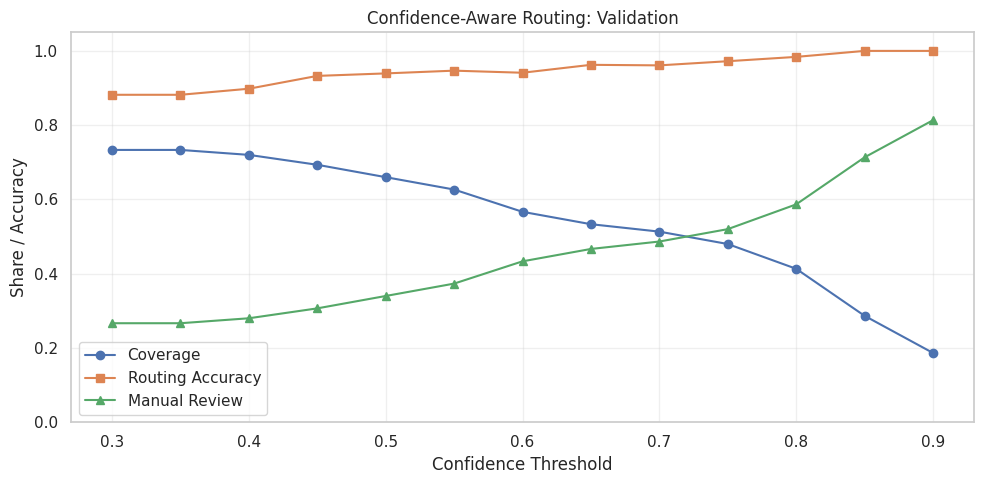

In [23]:

import matplotlib.pyplot as plt

thresholds = np.arange(0.30, 0.91, 0.05)
experiment_rows = []

for threshold in thresholds:
    auto = (
        (routing_val["confidence"] >= threshold)
        & (routing_val["p_high"] < 0.30)
    )

    coverage = auto.mean()

    accuracy = (
        (
            routing_val.loc[auto, "true_department"]
            == routing_val.loc[auto, "pred_department"]
        ).mean()
        if auto.any() else np.nan
    )

    urgent_missed = (
        auto
        & routing_val["true_urgency"].eq("high")
        & ~routing_val["pred_urgency"].eq("high")
    ).sum()

    experiment_rows.append({
        "Threshold": round(float(threshold), 2),
        "Coverage": coverage,
        "Routing Accuracy": accuracy,
        "Manual Review": 1 - coverage,
        "Missed Urgent Auto-Routed": int(urgent_missed)
    })

routing_experiments = pd.DataFrame(experiment_rows)

display(routing_experiments.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    routing_experiments["Threshold"],
    routing_experiments["Coverage"],
    marker="o", label="Coverage"
)
ax.plot(
    routing_experiments["Threshold"],
    routing_experiments["Routing Accuracy"],
    marker="s", label="Routing Accuracy"
)
ax.plot(
    routing_experiments["Threshold"],
    routing_experiments["Manual Review"],
    marker="^", label="Manual Review"
)

ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("Share / Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Confidence-Aware Routing: Validation")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("routing_threshold_analysis.png", dpi=200)
plt.show()

routing_experiments.to_csv(
    "routing_threshold_results.csv", index=False
)


In [24]:

import os
import json
import shutil

EXPORT_DIR = "complaint_app"
MODEL_DIR = os.path.join(EXPORT_DIR, "model")
os.makedirs(MODEL_DIR, exist_ok=True)

# Model weights
shutil.copy2(
    "kazroberta_multitask_best.pt",
    os.path.join(MODEL_DIR, "model.pt")
)

# Tokenizer
kaz_tokenizer.save_pretrained(MODEL_DIR)

# Configuration
config = {
    "model_name": KAZ_MODEL_NAME,
    "label_maps": label_maps,
    "targets": TARGETS,
    "confidence_threshold": 0.75,
    "urgent_review_threshold": 0.30,
    "max_length": 96,
    "sla_hours": {
        "high": 4,
        "medium": 24,
        "low": 72
    }
}

with open(
    os.path.join(MODEL_DIR, "config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Model exported successfully!")
print("Files:", os.listdir(MODEL_DIR))


Model exported successfully!
Files: ['model.pt', 'tokenizer_config.json', 'config.json', 'tokenizer.json']


# 11. Final Conclusion and Future Work

## 11.1 Project Summary

This project successfully investigated the application of classical machine learning and modern deep learning architectures to the automated classification and intelligent routing of university student complaints written in Kazakh.

The study implemented and evaluated four different modeling approaches: Linear SVM with character-level TF-IDF, BiLSTM with Attention, multilingual XLM-RoBERTa, and Kazakh-specific KazRoBERTa with Multi-Task Learning.

The experimental pipeline included dataset exploration, data preprocessing, training and validation procedures, model selection, independent test evaluation, confusion matrix analysis, error analysis, and confidence-aware routing experiments.

All four modeling approaches were successfully implemented and evaluated using the same dataset containing 1,000 student complaints. The dataset was divided into 700 training examples, 150 validation examples, and 150 test examples.

The models were evaluated across four classification tasks: complaint category, urgency, emotional tone, and responsible university department.

The experimental results provide useful insights into the relationship between architectural complexity, dataset size, language-specific pretraining, and practical classification effectiveness.

## 11.2 Final Model Comparison

The final model comparison was conducted using the held-out test dataset.

The results are summarized below.

| Model | Category F1 | Urgency F1 | Tone F1 | Department F1 | Mean Macro-F1 |
|---|---:|---:|---:|---:|---:|
| Linear SVM + TF-IDF | 0.9867 | 0.9722 | 1.0000 | 0.9334 | **0.9731** |
| KazRoBERTa Multi-Task | 0.9933 | 0.9510 | 0.9844 | 0.9128 | **0.9604** |
| BiLSTM + Attention | 0.9733 | 0.9790 | 1.0000 | 0.8642 | **0.9541** |
| XLM-RoBERTa Multi-Task | 0.9798 | 0.9313 | 0.9681 | 0.9000 | **0.9448** |

The results demonstrate that all four approaches achieved strong classification performance on the available test dataset.

However, the classical Linear SVM model achieved the highest overall mean Macro-F1 score of 0.9731, outperforming the more complex neural network and Transformer architectures.

KazRoBERTa ranked second with a mean Macro-F1 of 0.9604, followed by BiLSTM with 0.9541 and XLM-RoBERTa with 0.9448.

This result illustrates an important principle of applied machine learning: increased model complexity does not automatically result in higher predictive performance.

In relatively small and structured text classification datasets, carefully selected classical machine learning features can provide highly competitive results.

## 11.3 Key Finding 1: Classical Machine Learning Remains Highly Competitive

One of the most significant findings is the strong performance of Linear SVM with character-level TF-IDF features.

Despite its simpler architecture, the SVM model achieved the highest average classification performance across the four tasks.

The character-level representation appears particularly suitable for the short Kazakh complaint texts in this dataset, where recurring word fragments, suffixes, and terminology provide useful discriminatory information.

Additionally, the SVM classifier requires substantially less computational complexity than the pretrained Transformer models.

Unlike deep neural architectures, the classical pipeline does not require GPU-based fine-tuning and can be trained using relatively modest computing resources.

These findings suggest that classical machine learning remains a practical and effective choice for small-scale administrative text classification problems.

Nevertheless, the strong performance must be interpreted in the context of the dataset's limited size and repeated linguistic patterns.

The experiment does not establish that SVM would necessarily outperform Transformers on substantially larger, more diverse, or naturally collected university complaint datasets.

## 11.4 Key Finding 2: Language-Specific Transformers Can Be Effective

KazRoBERTa demonstrated strong performance across all four tasks and achieved the highest category classification Macro-F1 score of 0.9933.

It also performed better than XLM-RoBERTa on every classification task in the held-out test comparison.

This finding is consistent with the possibility that language-specific pretraining provides useful representations for Kazakh text processing.

KazRoBERTa also uses significantly fewer parameters than the implemented multilingual XLM-RoBERTa architecture, making it an interesting alternative when computational resources are limited.

However, the experimental results should not be interpreted as definitive evidence that language-specific models always outperform multilingual models.

Differences in architecture, pretraining data, optimization, random initialization, and hyperparameter selection may influence the outcome.

Furthermore, the current experiment was conducted using a relatively small dataset and a limited number of training runs.

More extensive experiments across several random seeds and larger datasets would be necessary to establish stronger conclusions.

## 11.5 Key Finding 3: Multi-Task Learning Supports Joint Prediction

The neural network and Transformer architectures were designed to perform four classification tasks simultaneously.

A shared encoder extracts textual representations, while separate classification heads predict complaint category, urgency, emotional tone, and responsible department.

This design allows a single neural model to generate several related predictions without requiring a completely independent encoder for each task.

Multi-task learning is particularly relevant for complaint analysis because the different labels describe interconnected aspects of the same message.

For example, a complaint about accommodation problems may belong to the campus environment category, have an urgent priority, express dissatisfaction, and require action from the facilities department.

Although the implemented multi-task models produced strong results, the experiments do not establish that joint training is superior to separate single-task Transformer models.

A direct single-task versus multi-task comparison would be a valuable extension of this research.

## 11.6 Key Finding 4: Department Prediction Is the Most Challenging Task

The results indicate that responsible department classification was generally the most difficult of the four tasks.

For the SVM model, department classification achieved a Macro-F1 of 0.9334, which was lower than its results for category, urgency, and tone.

The same general pattern was observed in the neural models.

Department classification requires more detailed interpretation because several departments may be responsible for problems belonging to the same broad category.

For example, complaints involving campus facilities and physical safety may contain overlapping terminology while requiring different administrative responses.

Similarly, academic and administrative complaints can involve related processes but belong to different organizational units.

These observations suggest that department prediction requires finer-grained distinctions than broad category classification.

Improving department prediction may therefore require more diverse training examples, clearer annotation guidelines, hierarchical classification techniques, or additional university-specific contextual information.

## 11.7 Key Finding 5: Urgency Classification Requires Special Attention

Urgency classification is particularly important because incorrect predictions may lead to delayed handling of complaints that require immediate attention.

The test dataset contained 38 complaints labeled as high urgency.

The number of high-urgency complaints incorrectly classified as less urgent was:

| Model | Missed High-Urgency Complaints |
|---|---:|
| Linear SVM | 3 / 38 |
| BiLSTM + Attention | 3 / 38 |
| KazRoBERTa | 5 / 38 |
| XLM-RoBERTa | 5 / 38 |

Although the overall urgency classification performance was high, these errors demonstrate that accuracy and Macro-F1 alone are insufficient to evaluate the operational safety of an automated complaint management system.

In practical scenarios, the consequences of incorrectly downgrading an urgent complaint may be more serious than those of assigning excessive priority to a routine request.

Therefore, future implementations should investigate cost-sensitive classification, urgency-specific recall, probability calibration, and human-in-the-loop escalation mechanisms.

Such improvements would help align the technical system with practical administrative requirements.

## 11.8 Confidence-Aware Routing Results

An additional experiment investigated how classification confidence can support automated complaint routing.

The implemented routing mechanism uses the minimum confidence across category, urgency, and department predictions, together with an additional high-urgency probability condition.

Different confidence thresholds were evaluated using the validation dataset.

The experiments revealed a clear trade-off between automatic routing coverage and accuracy.

At a confidence threshold of 0.30, approximately 73.33% of complaints could be processed automatically, with routing accuracy of 88.18% among automatically routed cases.

Increasing the threshold to 0.75 reduced coverage to 48.00%, while improving routing accuracy to 97.22%.

At a threshold of 0.85, routing accuracy reached 100% on the automatically processed validation cases, but coverage decreased to 28.67%.

These findings demonstrate that confidence thresholds can be used to control the balance between automation and manual administrative review.

However, a higher confidence threshold does not guarantee complete protection against harmful errors.

At the preliminary 0.75 threshold, one high-urgency complaint in the validation experiment was still automatically routed despite an incorrect urgency prediction.

The zero observed missed-urgency cases at a threshold of 0.85 should also not be interpreted as a guarantee of safety because of the limited validation sample.

Moreover, the model's softmax confidence scores were not independently calibrated, and the routing policy was evaluated using an experimental rather than operational university environment.

The confidence-aware routing approach should therefore be regarded as a prototype requiring additional verification before practical deployment.

## 11.9 Practical Implementation

In addition to the research experiments, the project implemented a working inference and routing pipeline based on KazRoBERTa.

The pipeline accepts a complaint written in Kazakh and returns several structured outputs:

1. Predicted complaint category.
2. Predicted urgency level.
3. Predicted emotional tone.
4. Suggested responsible department.
5. Classification confidence.
6. Estimated high-urgency probability.
7. Automatic routing or manual review decision.
8. Suggested service-level response target.

The inference pipeline was tested on newly written example complaints concerning examination schedules, accommodation problems, and tuition payment processing.

The model successfully generated structured predictions and suggested corresponding university departments for these examples.

For research demonstration, the project also exports the trained KazRoBERTa weights, tokenizer configuration, and label mappings.

These artifacts are intended to support a separate Streamlit-based application without requiring the model to be retrained whenever a new complaint is submitted.

The notebook itself remains focused on reproducible research, experimentation, model comparison, and evaluation.

## 11.10 Limitations of the Study

Despite the strong experimental results, this project has several limitations.

**First, the dataset is relatively small.** The 1,000 available complaints may not represent the full linguistic diversity of messages written by university students.

**Second, the dataset contains repeated textual structures.** Although exact duplicate texts were not found, similarity analysis identified highly similar complaint pairs across the experimental partitions. Because a group-aware split was not applied, some reported performance values may be optimistic.

**Third, the test set contains only 150 examples.** The limited sample size restricts the precision of performance estimates and makes small differences between models difficult to interpret.

**Fourth, the labels represent a predefined university complaint taxonomy.** The trained classifiers may not generalize directly to universities with different administrative structures or department responsibilities.

**Fifth, the neural models were evaluated under a limited experimental configuration.** More extensive hyperparameter searches, multiple random seeds, and statistical significance testing could improve the reliability of comparisons.

**Sixth, high classification confidence does not necessarily indicate a correct prediction.** The routing component uses uncalibrated model probabilities and requires further validation.

**Seventh, the system has not been evaluated in a real university administrative environment.** Actual complaints may contain slang, spelling errors, code-switching, unfamiliar terminology, or issues not represented in the training dataset.

Finally, the current model is intended to support human administrative decisions rather than independently resolve all student complaints.

## 11.11 Responsible AI and Ethical Considerations

Responsible AI is an essential consideration when designing systems that process student complaints.

Such messages may contain personal information, academic records, financial concerns, descriptions of harassment, or other sensitive details.

A practical deployment would therefore require appropriate access controls, secure data handling, retention policies, and clear institutional authorization.

Another concern is algorithmic bias. Models trained on a small or limited dataset may perform inconsistently across different writing styles, demographic groups, or categories of complaints.

Inaccurate urgency classification can also create operational risks if serious student concerns are handled too slowly.

To reduce these risks, the proposed system incorporates manual review for uncertain and potentially urgent cases.

However, human oversight should remain available even when the model expresses high confidence.

The system should provide recommendations rather than irreversible administrative decisions, and users should be informed that automated predictions may be incorrect.

A production implementation would also require monitoring, periodic evaluation, feedback collection, and mechanisms for correcting misclassified complaints.

## 11.12 Future Work

Several directions could improve the system's reliability and practical usefulness.

**1. Larger and more diverse Kazakh-language datasets.** Collecting real university complaints, with appropriate privacy safeguards and annotation procedures, would support more reliable evaluation.

**2. Improved urgency detection.** Cost-sensitive loss functions and urgency-specific optimization could reduce the number of serious complaints classified as less urgent.

**3. Single-task versus multi-task comparison.** Additional experiments could determine whether shared learning improves performance compared with separate Transformer classifiers.

**4. Probability calibration.** Techniques such as temperature scaling could make model confidence scores more meaningful for routing decisions.

**5. Robustness evaluation.** Testing on informal Kazakh, spelling errors, paraphrased complaints, and Kazakh–Russian code-switching would provide a better understanding of real-world generalization.

**6. Hierarchical classification.** A two-stage approach could first predict the broad complaint category and then identify the responsible department.

**7. Human feedback integration.** Administrators could correct model recommendations, creating a foundation for future dataset improvement and retraining.

**8. Web application development.** The exported KazRoBERTa model could be integrated into a standalone Streamlit application featuring complaint input, structured predictions, confidence visualization, and routing recommendations.

**9. Explainability.** Additional methods could investigate which words or phrases influence particular classifications, improving transparency for administrative users.

**10. Multi-university evaluation.** Testing on complaints from different universities would help determine whether the model can generalize beyond a single organizational structure.

## 11.13 Final Remarks

The project demonstrates that machine learning and deep learning can provide effective tools for structured classification of university student complaints written in Kazakh.

Four distinct modeling approaches were implemented and compared, including classical machine learning, recurrent neural networks, multilingual Transformers, and Kazakh-specific Transformer architectures.

The best overall test performance was achieved by Linear SVM with a mean Macro-F1 of 0.9731, while KazRoBERTa demonstrated competitive performance and provided the basis for a multi-task neural inference and routing pipeline.

The findings emphasize that successful AI development requires more than selecting the largest or most complex architecture.

Data quality, appropriate evaluation metrics, error analysis, operational constraints, model confidence, and human oversight are equally important.

The confidence-aware routing experiments further demonstrate the practical trade-off between automation efficiency and classification reliability.

Although the current system is a research prototype with limitations related to dataset size, linguistic diversity, and real-world validation, it provides a foundation for further work on Kazakh-language educational administration tools.

**In conclusion, the project successfully combines comparative AI research with a practical complaint-routing prototype, demonstrating both the capabilities and the limitations of automated decision support for university student services.**

In [25]:

import os
import shutil
from google.colab import files

MODEL_FOLDER = "/content/complaint_app/model"

assert os.path.exists(
    os.path.join(MODEL_FOLDER, "model.pt")
), "Model weights not found!"

archive = shutil.make_archive(
    "/content/KazRoBERTa_Trained_Model",
    "zip",
    root_dir="/content/complaint_app",
    base_dir="model"
)

print("Archive:", archive)
print("Size:", round(os.path.getsize(archive) / 1024**2, 2), "MB")

files.download(archive)


Archive: /content/KazRoBERTa_Trained_Model.zip
Size: 296.35 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>